In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# display settings (optional)
pd.set_option('display.max_columns', 50)
sns.set(style="whitegrid")

# ✅ Load from local file (correct path and syntax)
df = pd.read_csv(r"C:\AI-Course\covid-trend\owid-covid-data.csv")

# Preview first few rows
df.head()


,Entity,Day,"Cumulative excess deaths per 100,000 people (central estimate)","Cumulative excess deaths per 100,000 people (95% CI, lower bound)","Cumulative excess deaths per 100,000 people (95% CI, upper bound)","Total confirmed deaths due to COVID-19 per 100,000 people"
0,Afghanistan,2020-01-01,-0.022148,-0.289158,0.420465,NaN
1,Afghanistan,2020-01-06,-0.044295,-0.570486,0.848026,0.0
2,Afghanistan,2020-01-13,-0.047579,-0.837293,1.281982,0.0
3,Afghanistan,2020-01-20,0.022123,-1.125014,1.698806,0.0
4,Afghanistan,2020-01-27,0.063374,-1.377656,2.177791,0.0


In [27]:
# --- Step B: Explore and understand the dataset ---

# 1️⃣ Check the overall size of the dataset
print("Shape (rows, columns):", df.shape)

# 2️⃣ List all the available columns
print("\nColumns available:")
print(df.columns.tolist())

# 3️⃣ Check basic info: data types, non-null counts, memory usage
print("\nDataset info:")
df.info()

# 4️⃣ Peek at the first few rows for Nigeria (or any country you prefer)
print("\nSample rows for Nigeria:")
df[df["Entity"] == "Nigeria"].head()


Shape (rows, columns): (521314, 6)

Columns available:
['Entity', 'Day', 'Cumulative excess deaths per 100,000 people (central estimate)', 'Cumulative excess deaths per 100,000 people (95% CI, lower bound)', 'Cumulative excess deaths per 100,000 people (95% CI, upper bound)', 'Total confirmed deaths due to COVID-19 per 100,000 people']

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 521314 entries, 0 to 521313
Data columns (total 6 columns):
 #   Column                                                             Non-Null Count   Dtype  
---  ------                                                             --------------   -----  
 0   Entity                                                             521314 non-null  object 
 1   Day                                                                521314 non-null  object 
 2   Cumulative excess deaths per 100,000 people (central estimate)     55458 non-null   float64
 3   Cumulative excess deaths per 100,000 people (95

,Entity,Day,"Cumulative excess deaths per 100,000 people (central estimate)","Cumulative excess deaths per 100,000 people (95% CI, lower bound)","Cumulative excess deaths per 100,000 people (95% CI, upper bound)","Total confirmed deaths due to COVID-19 per 100,000 people"
330756,Nigeria,2020-01-01,0.335140,-0.219731,1.246738,NaN
330757,Nigeria,2020-01-06,0.670229,-0.364227,2.494107,0.0
330758,Nigeria,2020-01-13,1.058958,-0.468830,3.734287,0.0
330759,Nigeria,2020-01-20,1.439144,-0.635414,4.558249,0.0
330760,Nigeria,2020-01-27,1.817994,-0.795644,5.664027,0.0


In [28]:
# --- Step C: Rename columns for easier use ---

df = df.rename(columns={
    "Entity": "Country",
    "Day": "Date",
    "Cumulative excess deaths per 100,000 people (central estimate)": "Excess_Deaths_Est",
    "Cumulative excess deaths per 100,000 people (95% CI, lower bound)": "Excess_Deaths_Low",
    "Cumulative excess deaths per 100,000 people (95% CI, upper bound)": "Excess_Deaths_High",
    "Total confirmed deaths due to COVID-19 per 100,000 people": "Confirmed_Deaths_per100k"
})

print("✅ Columns renamed successfully!")
print(df.columns.tolist())


✅ Columns renamed successfully!
['Country', 'Date', 'Excess_Deaths_Est', 'Excess_Deaths_Low', 'Excess_Deaths_High', 'Confirmed_Deaths_per100k']


In [29]:
# --- Step D: Clean up and filter Nigeria's data ---

# 1️⃣ Convert 'Date' column from text (string) to real datetime objects
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# 2️⃣ Confirm it worked
print("✅ Date column converted successfully!")
print(df["Date"].dtype)

# 3️⃣ Filter data for Nigeria
nigeria = df[df["Country"] == "Nigeria"]

# 4️⃣ Check the first few rows
print("\nSample rows for Nigeria:")
print(nigeria.head())

# 5️⃣ Check how many records you have
print("\nNumber of records for Nigeria:", len(nigeria))



✅ Date column converted successfully!
datetime64[ns]

Sample rows for Nigeria:
        Country       Date  Excess_Deaths_Est  Excess_Deaths_Low  \
330756  Nigeria 2020-01-01           0.335140          -0.219731   
330757  Nigeria 2020-01-06           0.670229          -0.364227   
330758  Nigeria 2020-01-13           1.058958          -0.468830   
330759  Nigeria 2020-01-20           1.439144          -0.635414   
330760  Nigeria 2020-01-27           1.817994          -0.795644   

        Excess_Deaths_High  Confirmed_Deaths_per100k  
330756            1.246738                       NaN  
330757            2.494107                       0.0  
330758            3.734287                       0.0  
330759            4.558249                       0.0  
330760            5.664027                       0.0  

Number of records for Nigeria: 2089


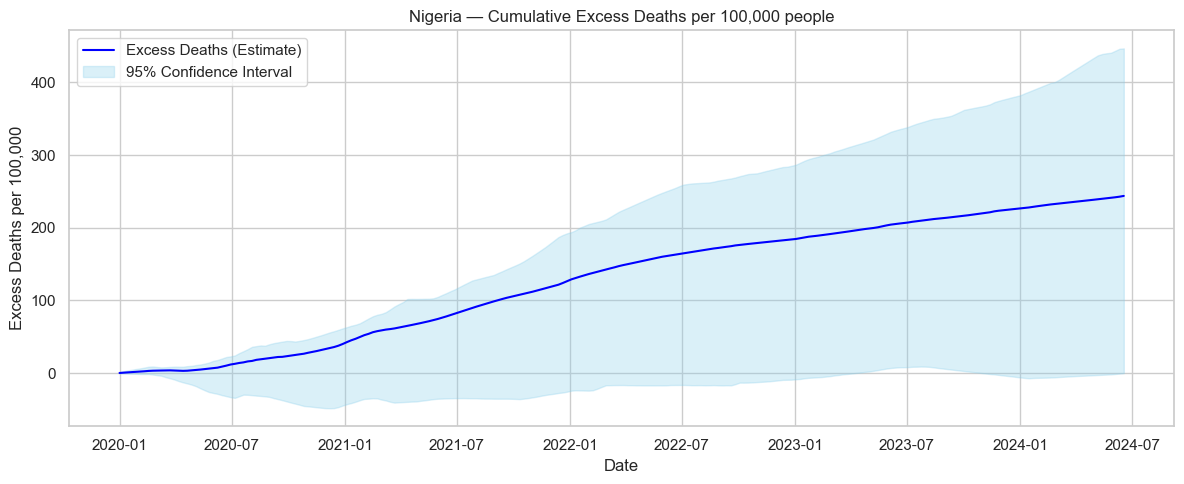

In [30]:
plt.figure(figsize=(12,5))
plt.plot(nigeria["Date"], nigeria["Excess_Deaths_Est"], label="Excess Deaths (Estimate)", color="blue")
plt.fill_between(
    nigeria["Date"],
    nigeria["Excess_Deaths_Low"],
    nigeria["Excess_Deaths_High"],
    color="skyblue", alpha=0.3, label="95% Confidence Interval"
)
plt.title("Nigeria — Cumulative Excess Deaths per 100,000 people")
plt.xlabel("Date")
plt.ylabel("Excess Deaths per 100,000")
plt.legend()
plt.tight_layout()
plt.show()


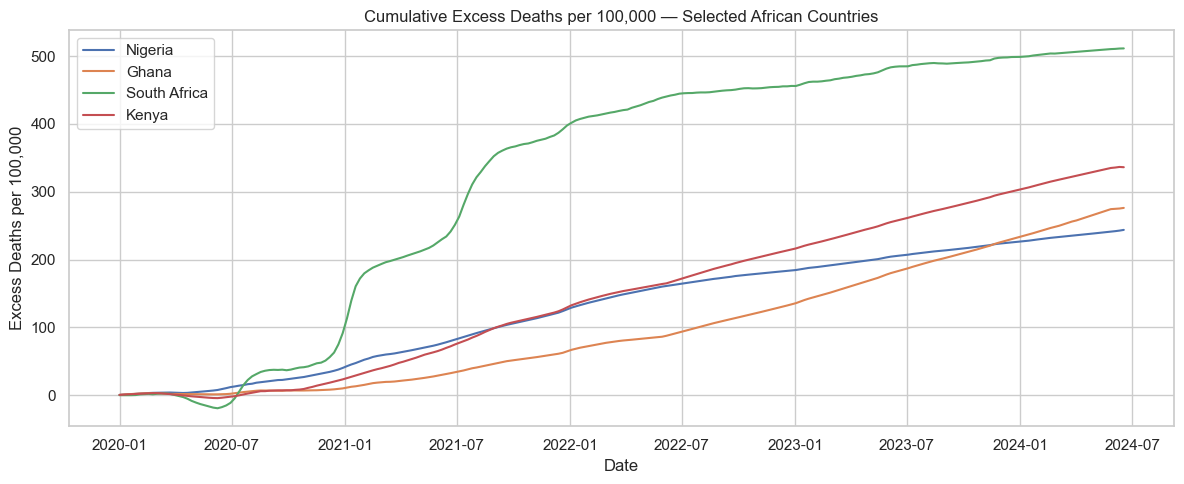

In [31]:
countries = ["Nigeria", "Ghana", "South Africa", "Kenya"]

plt.figure(figsize=(12,5))
for c in countries:
    subset = df[df["Country"] == c]
    plt.plot(subset["Date"], subset["Excess_Deaths_Est"], label=c)

plt.title("Cumulative Excess Deaths per 100,000 — Selected African Countries")
plt.xlabel("Date")
plt.ylabel("Excess Deaths per 100,000")
plt.legend()
plt.tight_layout()
plt.show()


In [32]:
nigeria = nigeria.sort_values("Date").copy()
nigeria["Excess_Deaths_Est"] = nigeria["Excess_Deaths_Est"].interpolate()
nigeria["Confirmed_Deaths_per100k"] = nigeria["Confirmed_Deaths_per100k"].fillna(0)


In [33]:
nigeria["Excess_Deaths_7d"] = nigeria["Excess_Deaths_Est"].rolling(window=7, min_periods=1).mean()


c:\AI-Course\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\AI-Course\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\AI-Course\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


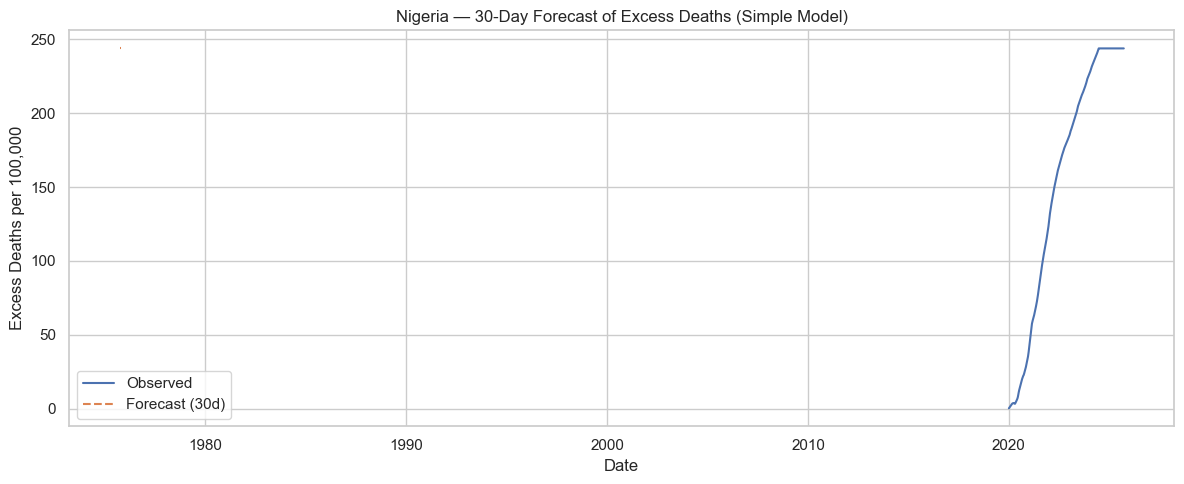

In [34]:
series = nigeria.set_index("Date")["Excess_Deaths_7d"].dropna()
model = ExponentialSmoothing(series, trend="add", seasonal=None, initialization_method="estimated")
fit = model.fit()
forecast = fit.forecast(30)  # next 30 days

plt.figure(figsize=(12,5))
plt.plot(series.index, series.values, label="Observed")
plt.plot(forecast.index, forecast.values, "--", label="Forecast (30d)")
plt.title("Nigeria — 30-Day Forecast of Excess Deaths (Simple Model)")
plt.xlabel("Date")
plt.ylabel("Excess Deaths per 100,000")
plt.legend()
plt.tight_layout()
plt.show()


In [35]:
nigeria.to_csv("nigeria_excess_deaths_clean.csv", index=False)
plt.savefig("nigeria_excess_deaths_trend.png", dpi=300, bbox_inches='tight')



<Figure size 640x480 with 0 Axes>